In [2]:
%load_ext autoreload
%autoreload 2

In [1]:
import json
from pathlib import Path

import dask
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr
from dask.diagnostics import ProgressBar

from cordex2energy.utils.constants import EXTENT_CH, EXTENT_BC, REFERENCE_PERIOD
from cordex2energy.utils.utils_xarray import sel_extent

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [2]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])

path_energy_ch = path_data_processed / "energy" / "ch"
path_energy_europe = path_data_processed / "energy" / "europe"

path_figs = Path(paths["path_figs"])

In [3]:
import os

os.environ["OMP_NUM_THREADS"] = "1"  # OpenMP
os.environ["MKL_NUM_THREADS"] = "1"  # MKL
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # OpenBLAS
os.environ["NUMEXPR_NUM_THREADS"] = "1"  # numexpr

In [4]:
dask.config.set(num_workers=15, threads_per_worker=16)
dask.config.set(
    {
        "distributed.worker.memory.target": 0.7,  # Spill to disk at 70%
        "distributed.worker.memory.spill": 0.8,  # Start spilling at 80%
        "distributed.worker.memory.pause": 0.9,  # Pause worker at 90%
        "array.chunk-size": "512MiB",
        "logging.distributed": "error",  # Less verbose logs
    }
)

# Functions

In [5]:
import regionmask
from xclim.sdba import loess


def analyze_europe_timeseries(ds, variable="tas", mask_ocean=True, loess_window=30):
    """Analyze variable over European land with yearly aggregation and LOESS smoothing.

    Args:
        ds: xarray Dataset with the variable
        variable: variable name to analyze
        mask_ocean: if True, mask ocean regions (keep only land)
        loess_window: window size for LOESS smoothing in years

    Returns:
        dict with years, raw values, and smoothed values
    """
    # Get the data
    da = ds[variable]

    # Create land/sea mask using regionmask
    if mask_ocean:
        print("  Creating land mask...")
        # Use Natural Earth land mask
        land_mask = regionmask.defined_regions.natural_earth_v5_0_0.land_110.mask(da.lon, da.lat)
        # Apply mask (keep only land)
        da = da.where(~np.isnan(land_mask))

    # Select Europe extent
    print("  Selecting European extent...")
    da = sel_extent(da, EXTENT_BC)

    # Remove any extra dimensions beyond lat, lon, time
    expected_dims = {"lat", "lon", "time"}
    extra_dims = set(da.dims) - expected_dims
    if extra_dims:
        print(f"  Removing extra dimensions: {extra_dims}")
        for dim in extra_dims:
            da = da.isel({dim: 0})

    # Yearly aggregation
    print("  Computing yearly means...")
    with ProgressBar(dt=2):
        yearly_mean = (
            da.groupby("time.year")
            .mean(dim="time")
            .mean(dim=["lat", "lon"])
            .compute()
        )

    years = yearly_mean.year.values
    values = yearly_mean.values

    # Apply LOESS smoothing using xclim
    print(f"  Applying LOESS smoothing (window={loess_window} years)...")
    # xclim loess expects DataArray with a dimension to smooth over
    da_yearly = xr.DataArray(
        values,
        coords={"year": years},
        dims=["year"]
    )

    # Apply loess smoothing with tricube weights
    # f parameter is the fraction of data points to use (window / total_points)
    f = loess_window / len(years)
    smoothed_da = loess.loess_smoothing(da_yearly, dim="year", f=f, niter=1, weights="tricube")
    smoothed = smoothed_da.values

    return {
        "years": years,
        "values": values,
        "smoothed": smoothed,
        "variable": variable,
        "units": da.attrs.get("units", ""),
    }

def plot_timeseries_comparison(results_dict, variable_name="Temperature", units="°C",
                                figsize=(16, 10), save_path=None):
    """Plot timeseries comparison for multiple model chains and scenarios.

    Args:
        results_dict: nested dict with structure {model_chain: {scenario: results}}
        variable_name: name of the variable for plot title
        units: units for y-axis label
        figsize: figure size tuple
        save_path: path to save figure (optional)
    """
    n_models = len(results_dict)

    fig, axes = plt.subplots(n_models, 1, figsize=figsize, sharex=True)
    if n_models == 1:
        axes = [axes]

    colors = {
        "rcp26": "#4575b4",  # Blue for low emissions
        "rcp85": "#d73027",  # Red for high emissions
    }

    for idx, (model_chain, scenarios_data) in enumerate(results_dict.items()):
        ax = axes[idx]

        # Plot each scenario
        for scenario, data in scenarios_data.items():
            color = colors.get(scenario, "gray")

            # Plot raw data as scatter
            ax.scatter(data["years"], data["values"],
                      alpha=0.3, s=20, color=color, label=f"{scenario.upper()} (yearly)")

            # Plot smoothed line
            ax.plot(data["years"], data["smoothed"],
                   linewidth=2.5, color=color, label=f"{scenario.upper()} (LOESS)")

        # Formatting
        ax.set_ylabel(f"{variable_name} ({units})", fontsize=11)
        ax.set_title(model_chain.replace("_", " "), fontsize=12, fontweight='bold')
        ax.legend(loc='upper left', framealpha=0.9)
        ax.grid(True, alpha=0.3)

        # Add reference period shading
        ax.axvspan(REFERENCE_PERIOD[0], REFERENCE_PERIOD[1],
                  alpha=0.1, color='gray', label='Reference Period' if idx == 0 else '')

    axes[-1].set_xlabel("Year", fontsize=11)

    plt.suptitle(f"{variable_name} Time Series - European Land (LOESS 30-year window)",
                fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Figure saved to {save_path}")

    plt.show()

    return fig, axes

# Trends and selection

In [6]:
model_chains = [
    "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1",
    # "MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1",
    "MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1",
]
climate_scenarios = ["rcp26", "rcp85"]

In [7]:
# Analyze temperature timeseries for all model chains and scenarios
results = {}

for model_chain in model_chains:
    results[model_chain] = {}

    for climate_scenario in climate_scenarios:
        print(f"\nProcessing {model_chain} - {climate_scenario}")

        # Load temperature data
        ds_tas = xr.open_zarr(
            path_data_processed / "cordex_processed" /
            f"{model_chain}_{climate_scenario}" / "bias_corrected" / "day" / "tas.zarr"
        )

        # Analyze the timeseries
        results[model_chain][climate_scenario] = analyze_europe_timeseries(
            ds_tas,
            variable="tas",
            mask_ocean=True,
            loess_window=30
        )

        print(f"  Processed {len(results[model_chain][climate_scenario]['years'])} years")

print("\n✓ Analysis complete!")


Processing CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1 - rcp26
  Creating land mask...
  Selecting European extent...
  Computing yearly means...
[                                        ] | 1% Completed | 2.01 s us

[#################                       ] | 44% Completed | 178.99 s


KeyboardInterrupt: 

In [ ]:
# Create a properly structured xarray Dataset
# First, collect all unique years and model/scenario combinations
all_years = set()
model_scenario_pairs = []

for model_chain, scenarios in results.items():
    for scenario, data in scenarios.items():
        all_years.update(data['years'])
        model_scenario_pairs.append((model_chain, scenario))

# Sort years
all_years = sorted(list(all_years))
n_years = len(all_years)
n_combinations = len(model_scenario_pairs)

# Create arrays to hold the data
tas_yearly = np.full((n_combinations, n_years), np.nan)
tas_smoothed = np.full((n_combinations, n_years), np.nan)

# Fill in the data
model_chain_labels = []
scenario_labels = []

for i, (model_chain, scenario) in enumerate(model_scenario_pairs):
    model_chain_labels.append(model_chain)
    scenario_labels.append(scenario)

    data = results[model_chain][scenario]
    for j, year in enumerate(data['years']):
        year_idx = all_years.index(year)
        tas_yearly[i, year_idx] = data['values'][j]
        tas_smoothed[i, year_idx] = data['smoothed'][j]

# Create xarray Dataset with proper dimensions
ds_results = xr.Dataset(
    {
        'tas_yearly': (['model_scenario', 'year'], tas_yearly),
        'tas_smoothed': (['model_scenario', 'year'], tas_smoothed),
    },
    coords={
        'year': all_years,
        'model_chain': (['model_scenario'], model_chain_labels),
        'scenario': (['model_scenario'], scenario_labels),
        'model_scenario': [f"{m}_{s}" for m, s in model_scenario_pairs],
    },
    attrs={
        'variable': 'tas',
        'units': 'K',
        'description': 'European land-averaged near-surface air temperature',
        'smoothing': 'LOESS 30-year window'
    }
)

ds_results

NameError: name 'results' is not defined

In [12]:
ds_results.to_netcdf("year_selection/loess_smoothed_tas.nc")

In [8]:
# Create a properly structured xarray Dataset
# First, collect all unique years and model/scenario combinations
all_years = set()
model_scenario_pairs = []

for model_chain in model_chains:
    for scenario in climate_scenarios:
        model_scenario_pairs.append((model_chain, scenario))
ds_results = xr.open_dataset("year_selection/loess_smoothed_tas.nc")

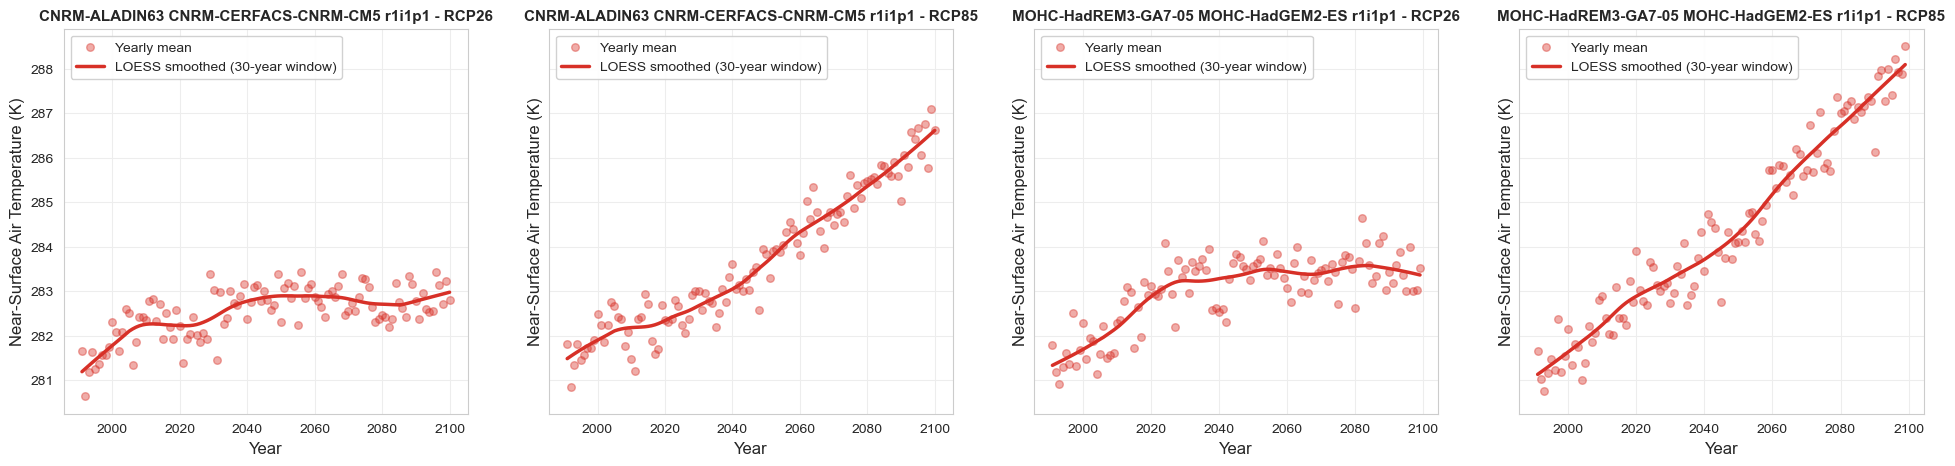

In [9]:
fig, axes = plt.subplots(1, len(model_scenario_pairs), figsize=(6*len(model_scenario_pairs), 5), sharey=True)
for i in range(4):
    ax = axes[i]
    single_model = ds_results["model_chain"].isel(model_scenario=i).item()
    single_scenario = ds_results["scenario"].isel(model_scenario=i).item()
    units = ds_results.attrs.get("units", "")
    ds_results["tas_yearly"].isel(model_scenario=i).plot.scatter(ax=ax, alpha=0.4, s=30, color="#d73027", label="Yearly mean")
    ds_results["tas_smoothed"].isel(model_scenario=i).plot(ax=ax, linewidth=2.5, color="#d73027", label="LOESS smoothed (30-year window)")
    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel(f"Near-Surface Air Temperature ({units})", fontsize=12)
    ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
                fontsize=11, fontweight='bold')
    ax.legend(loc='upper left', framealpha=0.9)
plt.show()


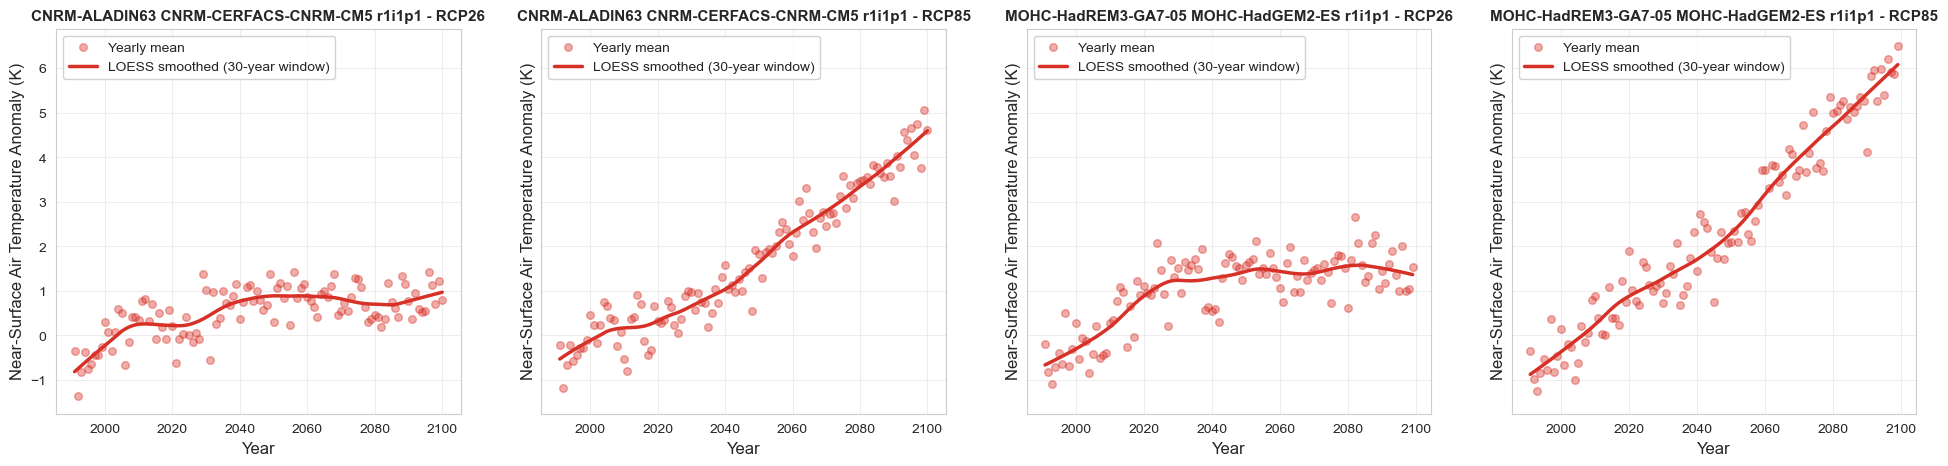

In [10]:
fig, axes = plt.subplots(1, len(model_scenario_pairs), figsize=(6*len(model_scenario_pairs), 5), sharey=True)
for i in range(4):
    ax = axes[i]
    single_model = ds_results["model_chain"].isel(model_scenario=i).item()
    single_scenario = ds_results["scenario"].isel(model_scenario=i).item()
    units = ds_results.attrs.get("units", "")
    mean_ref = ds_results["tas_yearly"].isel(model_scenario=i).sel(year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1])+1)).mean(dim="year").item()
    (ds_results["tas_yearly"].isel(model_scenario=i) - mean_ref).plot.scatter(ax=ax, alpha=0.4, s=30, color="#d73027", label="Yearly mean")
    (ds_results["tas_smoothed"].isel(model_scenario=i) - mean_ref).plot(ax=ax, linewidth=2.5, color="#d73027", label="LOESS smoothed (30-year window)")
    ax.set_xlabel("Year", fontsize=12)
    ax.set_ylabel(f"Near-Surface Air Temperature Anomaly ({units})", fontsize=12)
    ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
                fontsize=11, fontweight='bold')
    ax.legend(loc='upper left', framealpha=0.9)
plt.show()


In [33]:
df_cost_26 = pd.read_csv("year_selection/total_system_cost_RCP26.csv")
df_cost_26.index = np.arange(2018, 2053)

<Axes: >

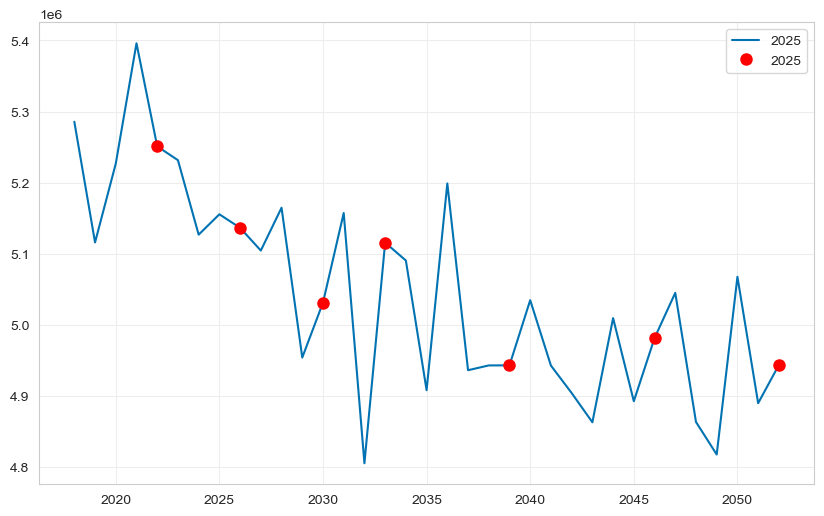

In [45]:
selected_years_26 = [2022, 2026, 2030, 2033, 2039, 2046, 2052]
fig, ax = plt.subplots(figsize=(10, 6))
df_cost_26.plot(ax=ax)
df_cost_26.loc[selected_years_26].plot(style='o', color='red', markersize=8, ax=ax)

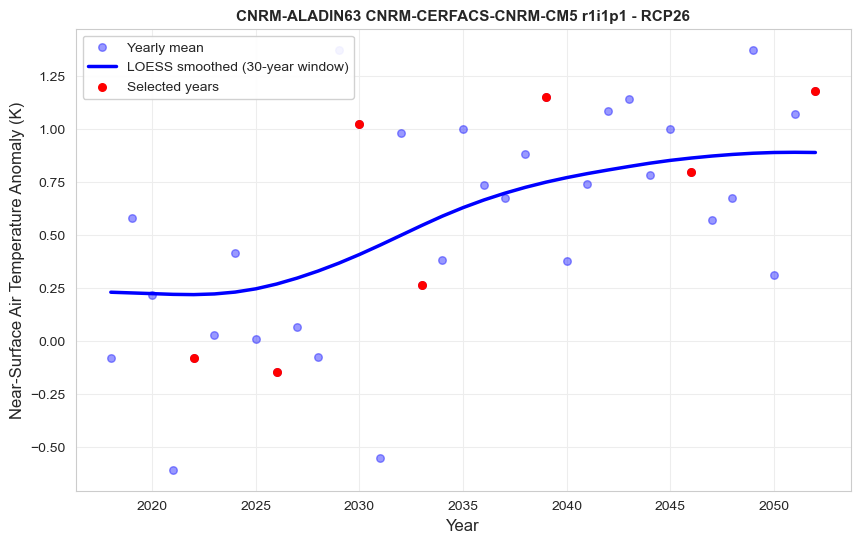

In [46]:
fig, ax = plt.subplots(figsize=(10, 6))
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
single_model = ds_results["model_chain"].sel(model_scenario=model).item()
single_scenario = ds_results["scenario"].sel(model_scenario=model).item()
units = ds_results.attrs.get("units", "")
years_to_show = np.arange(2018, 2053)
mean_ref = ds_results["tas_yearly"].sel(model_scenario=model).sel(year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1])+1)).mean(dim="year").item()
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot.scatter(ax=ax, alpha=0.4, s=30, color="blue", label="Yearly mean")
(ds_results["tas_smoothed"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot(ax=ax, linewidth=2.5, color="blue", label="LOESS smoothed (30-year window)")
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=selected_years_26).plot.scatter(ax=ax, alpha=1, s=30, color="red", label="Selected years")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(f"Near-Surface Air Temperature Anomaly ({units})", fontsize=12)
ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
            fontsize=11, fontweight='bold')
ax.legend(loc='upper left', framealpha=0.9)

<Axes: >

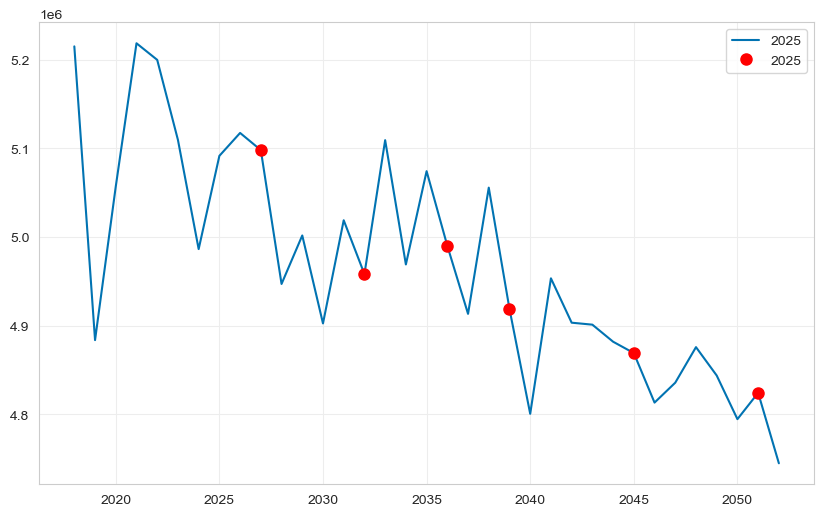

In [47]:
selected_years_85 = [2027, 2032, 2036, 2039, 2045, 2051]
df_cost_85 = pd.read_csv("year_selection/total_system_cost_RCP85.csv")
df_cost_85.index = np.arange(2018, 2053)
fig, ax = plt.subplots(figsize=(10, 6))
df_cost_85.plot(ax=ax)
df_cost_85.loc[selected_years_85].plot(style='o', color='red', markersize=8, ax=ax)

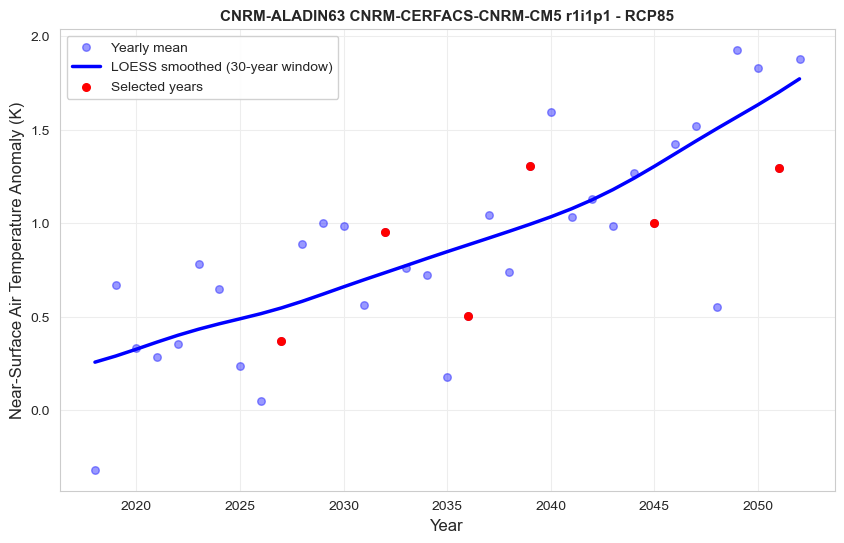

In [48]:
fig, ax = plt.subplots(figsize=(10, 6))
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
single_model = ds_results["model_chain"].sel(model_scenario=model).item()
single_scenario = ds_results["scenario"].sel(model_scenario=model).item()
units = ds_results.attrs.get("units", "")
years_to_show = np.arange(2018, 2053)
mean_ref = ds_results["tas_yearly"].sel(model_scenario=model).sel(year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1])+1)).mean(dim="year").item()
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot.scatter(ax=ax, alpha=0.4, s=30, color="blue", label="Yearly mean")
(ds_results["tas_smoothed"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot(ax=ax, linewidth=2.5, color="blue", label="LOESS smoothed (30-year window)")
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=selected_years_85).plot.scatter(ax=ax, alpha=1, s=30, color="red", label="Selected years")
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(f"Near-Surface Air Temperature Anomaly ({units})", fontsize=12)
ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
            fontsize=11, fontweight='bold')
ax.legend(loc='upper left', framealpha=0.9)

In [49]:
# For every 5-year window from 2018 to 2052, find the year with the closest yearly mean to the LOESS smoothed value
selected_years_dict = {}

for model_scenario in ds_results.model_scenario.values:
    selected_years_list = []

    # Define 5-year windows from 2018 to 2052
    start_year = 2018
    end_year = 2052
    window_size = 5

    for window_start in range(start_year, end_year, window_size):
        window_end = min(window_start + window_size - 1, end_year)
        window_years = np.arange(window_start, window_end + 1)

        # Get data for this window
        tas_yearly_window = ds_results["tas_yearly"].sel(model_scenario=model_scenario, year=window_years)
        tas_smoothed_window = ds_results["tas_smoothed"].sel(model_scenario=model_scenario, year=window_years)

        # Calculate absolute differences
        differences = np.abs(tas_yearly_window - tas_smoothed_window)

        # Find year with minimum difference
        min_diff_idx = differences.argmin().item()
        selected_year = window_years[min_diff_idx]
        selected_years_list.append(selected_year)

    selected_years_dict[model_scenario] = selected_years_list

    print(f"{model_scenario}:")
    print(f"  Selected years: {selected_years_list}")
    print()

print("Summary of selected years by model and scenario:")
for model_scenario, years in selected_years_dict.items():
    print(f"{model_scenario}: {years}")

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26:
  Selected years: [2020, 2024, 2028, 2037, 2041, 2044, 2051]

CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85:
  Selected years: [2020, 2027, 2031, 2033, 2042, 2044, 2052]

MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26:
  Selected years: [2021, 2023, 2029, 2033, 2039, 2043, 2048]

MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85:
  Selected years: [2019, 2026, 2029, 2033, 2038, 2044, 2051]

Summary of selected years by model and scenario:
CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26: [2020, 2024, 2028, 2037, 2041, 2044, 2051]
CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85: [2020, 2027, 2031, 2033, 2042, 2044, 2052]
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp26: [2021, 2023, 2029, 2033, 2039, 2043, 2048]
MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1_rcp85: [2019, 2026, 2029, 2033, 2038, 2044, 2051]


/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/plot/dataarray_plot.py:1268: UserWarning: You passed a edgecolor/edgecolors ('darkred') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  return ax.scatter(plts_np[0], plts_np[1], **kwargs)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/plot/dataarray_plot.py:1268: UserWarning: You passed a edgecolor/edgecolors ('darkred') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  return ax.scatter(plts_np[0], plts_np[1], **kwargs)


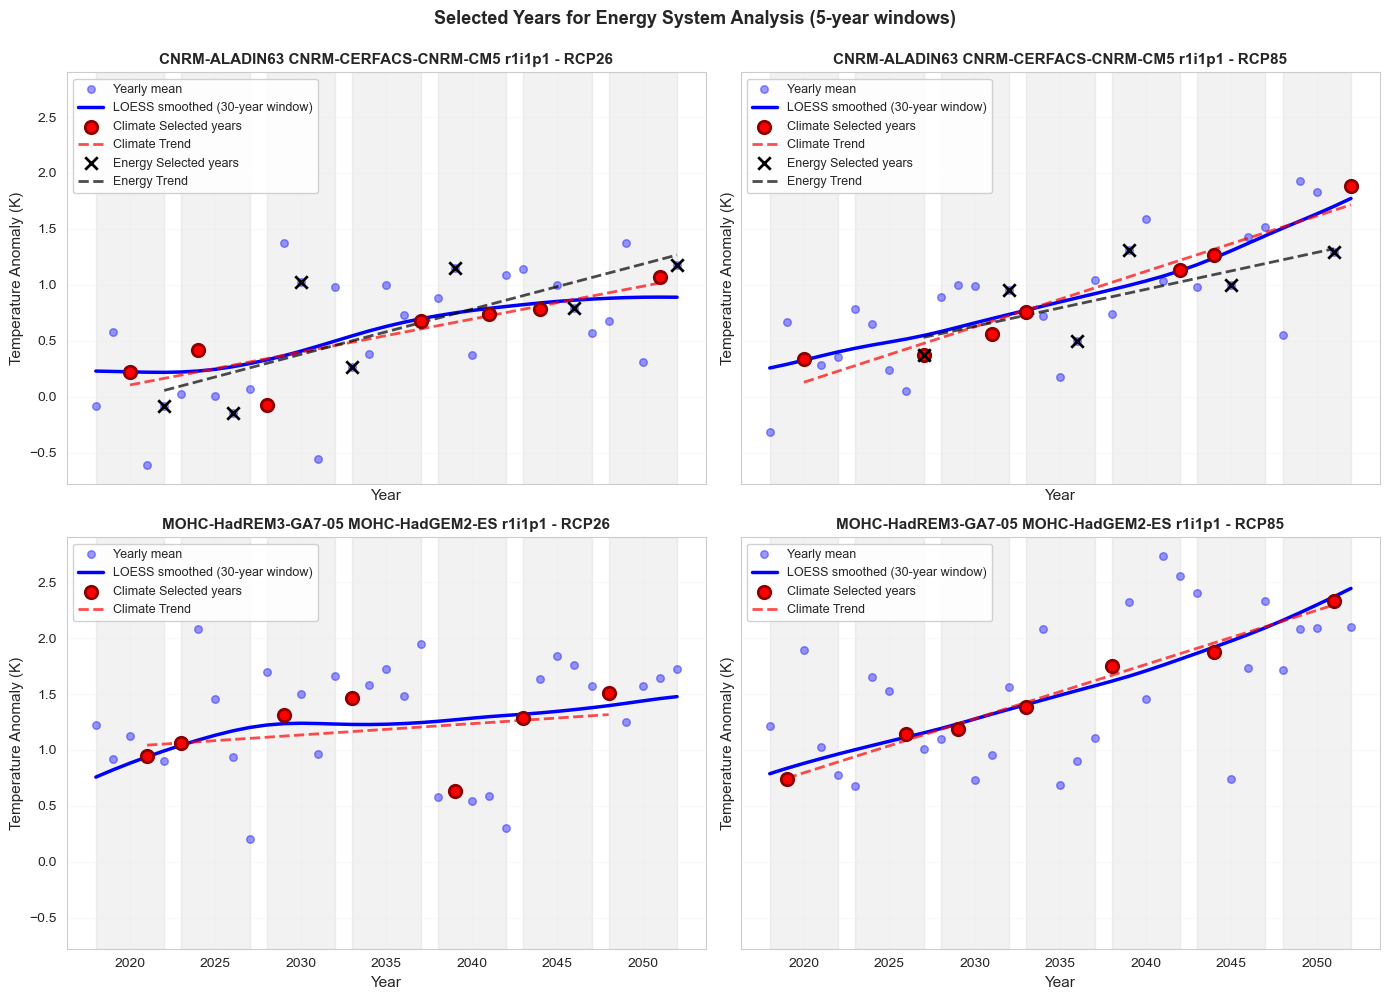

In [50]:
# Create a 2x2 plot for all model-scenario combinations
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

years_to_show = np.arange(2018, 2053)
window_start_years = np.arange(2018, 2053, 5)
for i, model_scenario in enumerate(ds_results.model_scenario.values):
    ax = axes[i]

    # Extract model and scenario info
    single_model = ds_results["model_chain"].sel(model_scenario=model_scenario).item()
    single_scenario = ds_results["scenario"].sel(model_scenario=model_scenario).item()

    # Calculate reference mean
    mean_ref = ds_results["tas_yearly"].sel(model_scenario=model_scenario).sel(
        year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1])+1)
    ).mean(dim="year").item()

    # Get selected years for this model-scenario combination
    selected_years_for_model = selected_years_dict[model_scenario]

    # Plot yearly mean as scatter
    (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=years_to_show
    ).plot.scatter(ax=ax, alpha=0.4, s=30, color="blue", label="Yearly mean")

    # Plot LOESS smoothed line
    (ds_results["tas_smoothed"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=years_to_show
    ).plot(ax=ax, linewidth=2.5, color="blue", label="LOESS smoothed (30-year window)")

    # Plot selected years
    (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=selected_years_for_model
    ).plot.scatter(ax=ax, alpha=1, s=80, color="red", marker='o',
                   edgecolors='darkred', linewidths=2, label="Climate Selected years", zorder=5)

    # Add trend line for climate selected years
    climate_temps = (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=selected_years_for_model
    ).values
    z_climate = np.polyfit(selected_years_for_model, climate_temps, 1)
    p_climate = np.poly1d(z_climate)
    ax.plot(selected_years_for_model, p_climate(selected_years_for_model),
            linestyle='--', color='red', linewidth=2, alpha=0.7, label='Climate Trend')

    # Plot energy selected years (only for CNRM model)
    if single_model.startswith("CNRM"):
        energy_selected_years = selected_years_26 if single_scenario == "rcp26" else selected_years_85
        (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
            year=energy_selected_years
        ).plot.scatter(ax=ax, alpha=1, s=80, color="black", marker='x',
                    edgecolors='darkred', linewidths=2, label="Energy Selected years", zorder=5)

        # Add trend line for energy selected years
        energy_temps = (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
            year=energy_selected_years
        ).values
        z_energy = np.polyfit(energy_selected_years, energy_temps, 1)
        p_energy = np.poly1d(z_energy)
        ax.plot(energy_selected_years, p_energy(energy_selected_years),
                linestyle='--', color='black', linewidth=2, alpha=0.7, label='Energy Trend')

    for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)

    # Formatting
    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel(f"Temperature Anomaly (K)", fontsize=11)
    ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
                 fontsize=11, fontweight='bold')
    ax.legend(loc='upper left', framealpha=0.9, fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Selected Years for Energy System Analysis (5-year windows)",
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/plot/dataarray_plot.py:1268: UserWarning: You passed a edgecolor/edgecolors ('darkred') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  return ax.scatter(plts_np[0], plts_np[1], **kwargs)
/home/yhaddad/.conda/envs/bias_correction_2024/lib/python3.11/site-packages/xarray/plot/dataarray_plot.py:1268: UserWarning: You passed a edgecolor/edgecolors ('darkred') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  return ax.scatter(plts_np[0], plts_np[1], **kwargs)


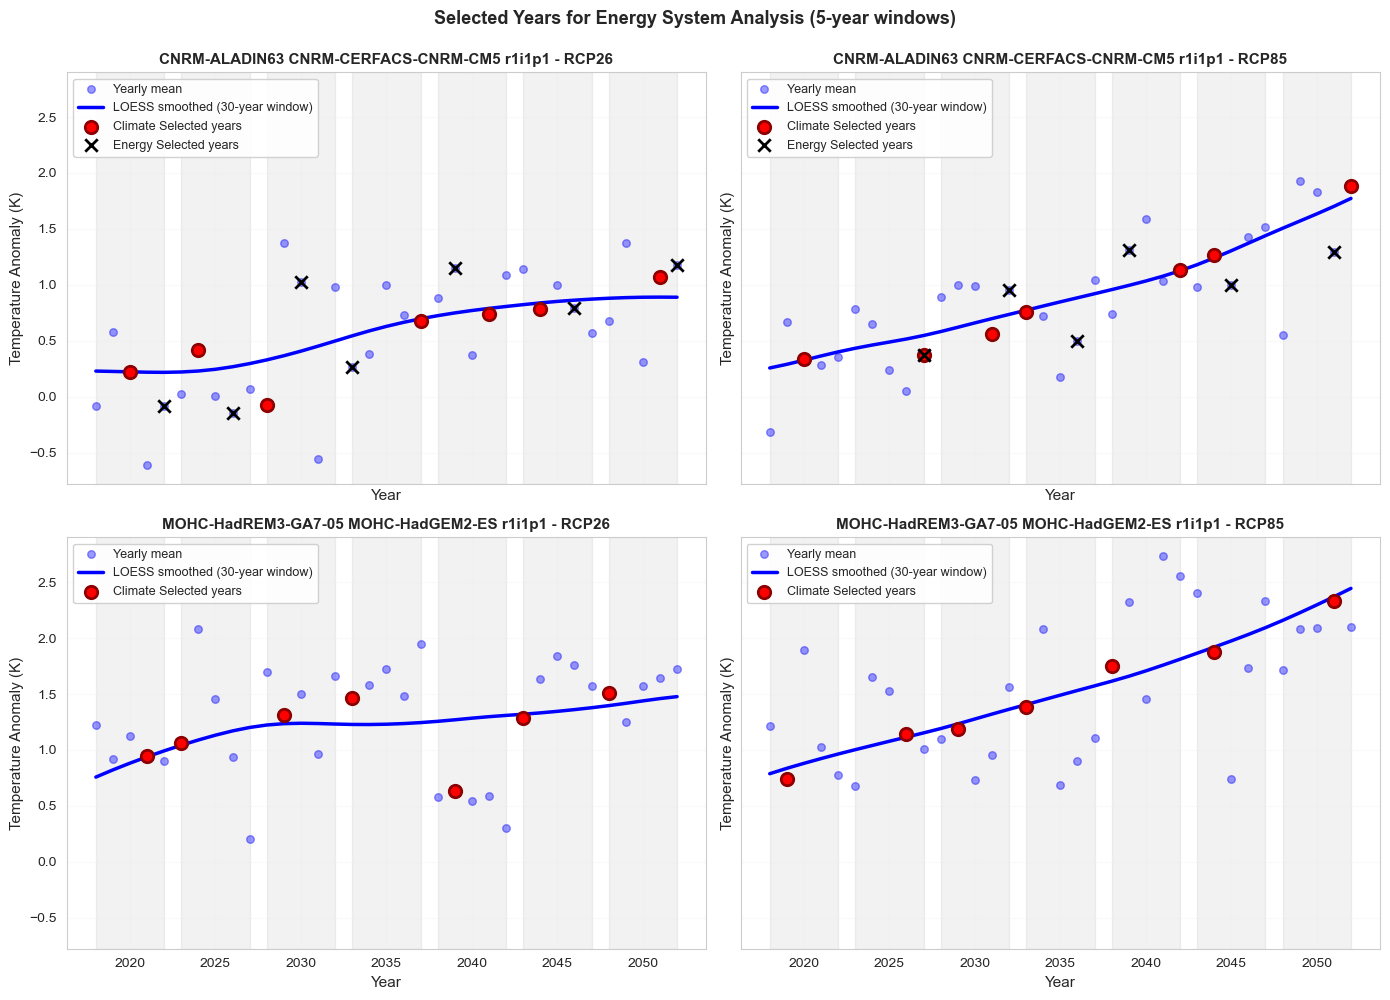

In [51]:
# Create a 2x2 plot for all model-scenario combinations
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

years_to_show = np.arange(2018, 2053)
window_start_years = np.arange(2018, 2053, 5)
for i, model_scenario in enumerate(ds_results.model_scenario.values):
    ax = axes[i]

    # Extract model and scenario info
    single_model = ds_results["model_chain"].sel(model_scenario=model_scenario).item()
    single_scenario = ds_results["scenario"].sel(model_scenario=model_scenario).item()

    # Calculate reference mean
    mean_ref = ds_results["tas_yearly"].sel(model_scenario=model_scenario).sel(
        year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1])+1)
    ).mean(dim="year").item()

    # Get selected years for this model-scenario combination
    selected_years_for_model = selected_years_dict[model_scenario]

    # Plot yearly mean as scatter
    (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=years_to_show
    ).plot.scatter(ax=ax, alpha=0.4, s=30, color="blue", label="Yearly mean")

    # Plot LOESS smoothed line
    (ds_results["tas_smoothed"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=years_to_show
    ).plot(ax=ax, linewidth=2.5, color="blue", label="LOESS smoothed (30-year window)")

    # Plot selected years
    (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
        year=selected_years_for_model
    ).plot.scatter(ax=ax, alpha=1, s=80, color="red", marker='o',
                   edgecolors='darkred', linewidths=2, label="Climate Selected years", zorder=5)

    # Plot selected years
    if single_model.startswith("CNRM"):
        (ds_results["tas_yearly"].sel(model_scenario=model_scenario) - mean_ref).sel(
            year=selected_years_26 if single_scenario == "rcp26" else selected_years_85
        ).plot.scatter(ax=ax, alpha=1, s=80, color="black", marker='x',
                    edgecolors='darkred', linewidths=2, label="Energy Selected years", zorder=5)

    for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)

    # Formatting
    ax.set_xlabel("Year", fontsize=11)
    ax.set_ylabel(f"Temperature Anomaly (K)", fontsize=11)
    ax.set_title(f"{single_model.replace('_', ' ')} - {single_scenario.upper()}",
                 fontsize=11, fontweight='bold')
    ax.legend(loc='upper left', framealpha=0.9, fontsize=9)
    ax.grid(True, alpha=0.3)

plt.suptitle("Selected Years for Energy System Analysis (5-year windows)",
             fontsize=13, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

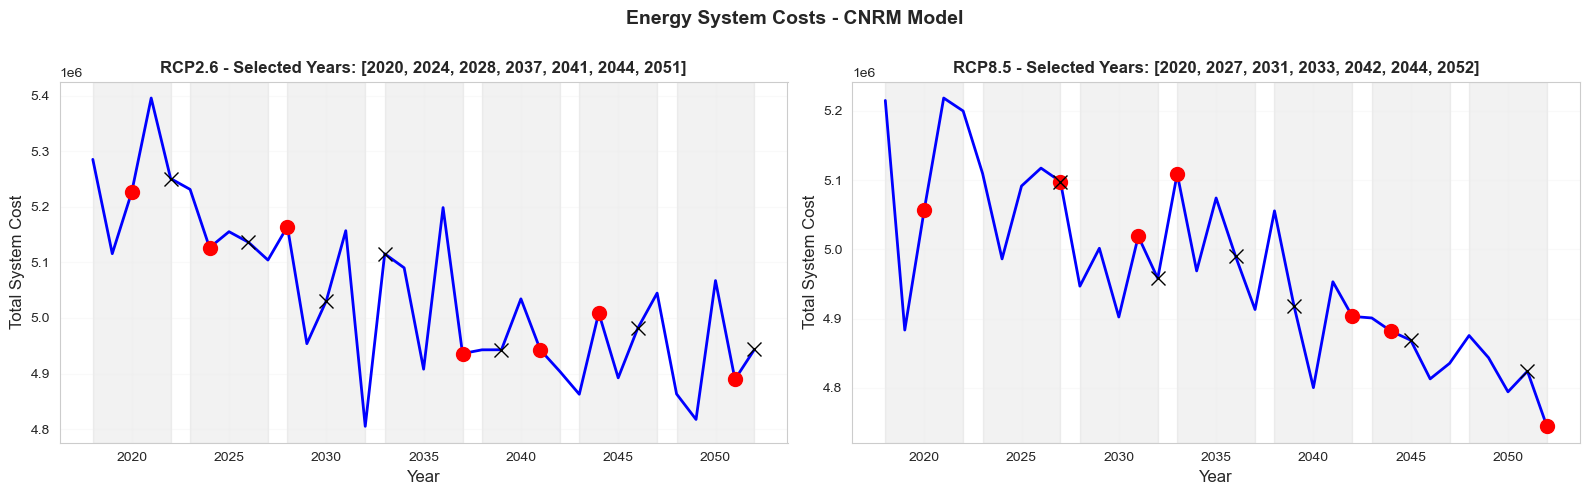

In [52]:
# Plot costs for CNRM model with selected years from the automated selection
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RCP26
ax = axes[0]
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
climate_selected_years_26 = selected_years_dict[model]
df_cost_26.plot(ax=ax, legend=False, color='blue', linewidth=2)
df_cost_26.loc[climate_selected_years_26].plot(style='o', color='red', markersize=10, ax=ax, legend=False)
df_cost_26.loc[selected_years_26].plot(style='x', color='black', markersize=10, ax=ax, legend=False)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total System Cost", fontsize=12)
ax.set_title(f"RCP2.6 - Selected Years: {climate_selected_years_26}", fontsize=12, fontweight='bold')
for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)
ax.grid(True, alpha=0.3)


# RCP85
ax = axes[1]
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
climate_selected_years_85 = selected_years_dict[model]
df_cost_85.plot(ax=ax, legend=False, color='blue', linewidth=2)
df_cost_85.loc[climate_selected_years_85].plot(style='o', color='red', markersize=10, ax=ax, legend=False)
df_cost_85.loc[selected_years_85].plot(style='x', color='black', markersize=10, ax=ax, legend=False)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total System Cost", fontsize=12)
ax.set_title(f"RCP8.5 - Selected Years: {climate_selected_years_85}", fontsize=12, fontweight='bold')
for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)
ax.grid(True, alpha=0.3)

plt.suptitle("Energy System Costs - CNRM Model", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [53]:
selected_years_26

[2022, 2026, 2030, 2033, 2039, 2046, 2052]

In [54]:
selected_years_85

[2027, 2032, 2036, 2039, 2045, 2051]

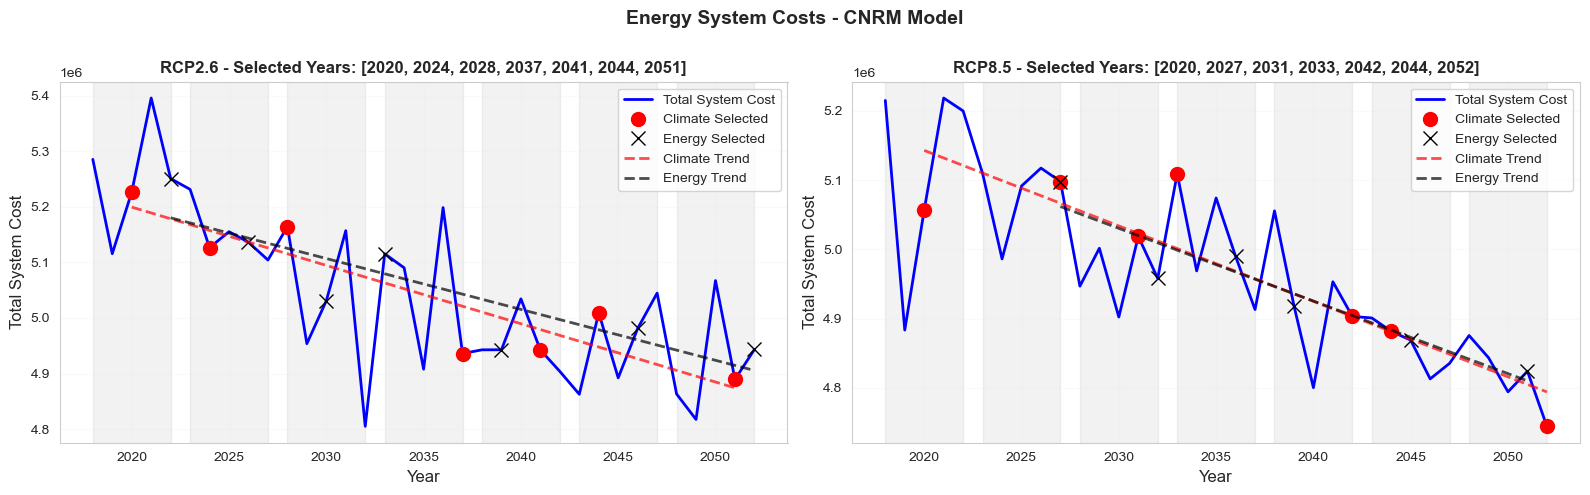

In [55]:

# Plot costs for CNRM model with selected years from the automated selection
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# RCP26
ax = axes[0]
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
climate_selected_years_26 = selected_years_dict[model]

n0 = len(ax.lines)
df_cost_26.plot(ax=ax, legend=False, color='blue', linewidth=2)
for l in ax.lines[n0:]: l.set_label('Total System Cost')

n1 = len(ax.lines)
df_cost_26.loc[climate_selected_years_26].plot(style='o', color='red', markersize=10, ax=ax, legend=False)
for l in ax.lines[n1:]: l.set_label('Climate Selected')

n2 = len(ax.lines)
df_cost_26.loc[selected_years_26].plot(style='x', color='black', markersize=10, ax=ax, legend=False)
for l in ax.lines[n2:]: l.set_label('Energy Selected')

# Climate selected years trend
climate_costs_26 = df_cost_26.loc[climate_selected_years_26].values.flatten()
z_climate_26 = np.polyfit(climate_selected_years_26, climate_costs_26, 1)
p_climate_26 = np.poly1d(z_climate_26)
ax.plot(climate_selected_years_26, p_climate_26(climate_selected_years_26),
        linestyle='--', color='red', linewidth=2, alpha=0.7, label='Climate Trend')

# Energy selected years trend
energy_costs_26 = df_cost_26.loc[selected_years_26].values.flatten()
z_energy_26 = np.polyfit(selected_years_26, energy_costs_26, 1)
p_energy_26 = np.poly1d(z_energy_26)
ax.plot(selected_years_26, p_energy_26(selected_years_26),
        linestyle='--', color='black', linewidth=2, alpha=0.7, label='Energy Trend')

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total System Cost", fontsize=12)
ax.set_title(f"RCP2.6 - Selected Years: {climate_selected_years_26}", fontsize=12, fontweight='bold')
for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize=10)

# RCP85
ax = axes[1]
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
climate_selected_years_85 = selected_years_dict[model]

n0 = len(ax.lines)
df_cost_85.plot(ax=ax, legend=False, color='blue', linewidth=2)
for l in ax.lines[n0:]: l.set_label('Total System Cost')

n1 = len(ax.lines)
df_cost_85.loc[climate_selected_years_85].plot(style='o', color='red', markersize=10, ax=ax, legend=False)
for l in ax.lines[n1:]: l.set_label('Climate Selected')

n2 = len(ax.lines)
df_cost_85.loc[selected_years_85].plot(style='x', color='black', markersize=10, ax=ax, legend=False)
for l in ax.lines[n2:]: l.set_label('Energy Selected')

# Climate selected years trend
climate_costs_85 = df_cost_85.loc[climate_selected_years_85].values.flatten()
z_climate_85 = np.polyfit(climate_selected_years_85, climate_costs_85, 1)
p_climate_85 = np.poly1d(z_climate_85)
ax.plot(climate_selected_years_85, p_climate_85(climate_selected_years_85),
        linestyle='--', color='red', linewidth=2, alpha=0.7, label='Climate Trend')

# Energy selected years trend
energy_costs_85 = df_cost_85.loc[selected_years_85].values.flatten()
z_energy_85 = np.polyfit(selected_years_85, energy_costs_85, 1)
p_energy_85 = np.poly1d(z_energy_85)
ax.plot(selected_years_85, p_energy_85(selected_years_85),
        linestyle='--', color='black', linewidth=2, alpha=0.7, label='Energy Trend')

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total System Cost", fontsize=12)
ax.set_title(f"RCP8.5 - Selected Years: {climate_selected_years_85}", fontsize=12, fontweight='bold')
for start_year in window_start_years:
        ax.axvspan(start_year, start_year + 4, color='gray', alpha=0.1, zorder=0)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize=10)

plt.suptitle("Energy System Costs - CNRM Model", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


# 2026.03.13

In [26]:
df_cost_26 = pd.read_csv("year_selection/2026.03.13/total_system_cost_RCP26.csv").set_index("year")

<Axes: xlabel='year'>

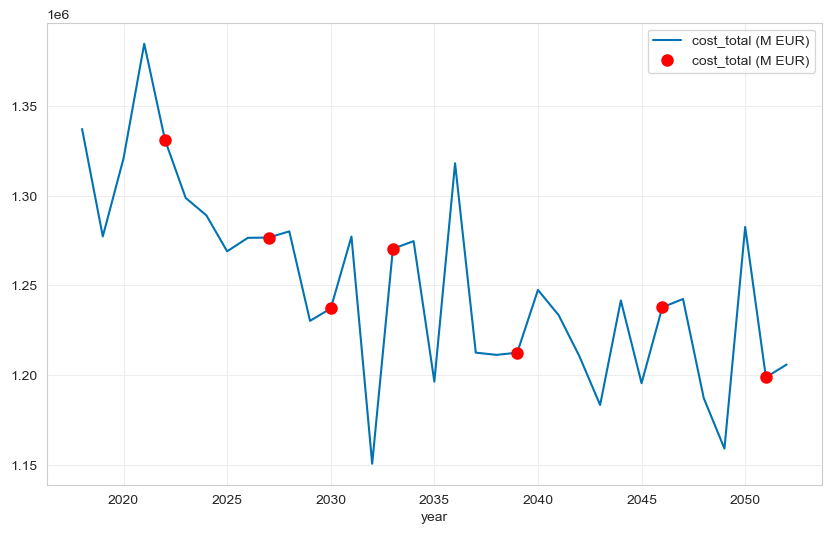

In [28]:
selected_years_26 = [2022, 2027, 2030, 2033, 2039, 2046, 2051]
fig, ax = plt.subplots(figsize=(10, 6))
df_cost_26.plot(ax=ax)
df_cost_26.loc[selected_years_26].plot(style='o', color='red', markersize=8, ax=ax)

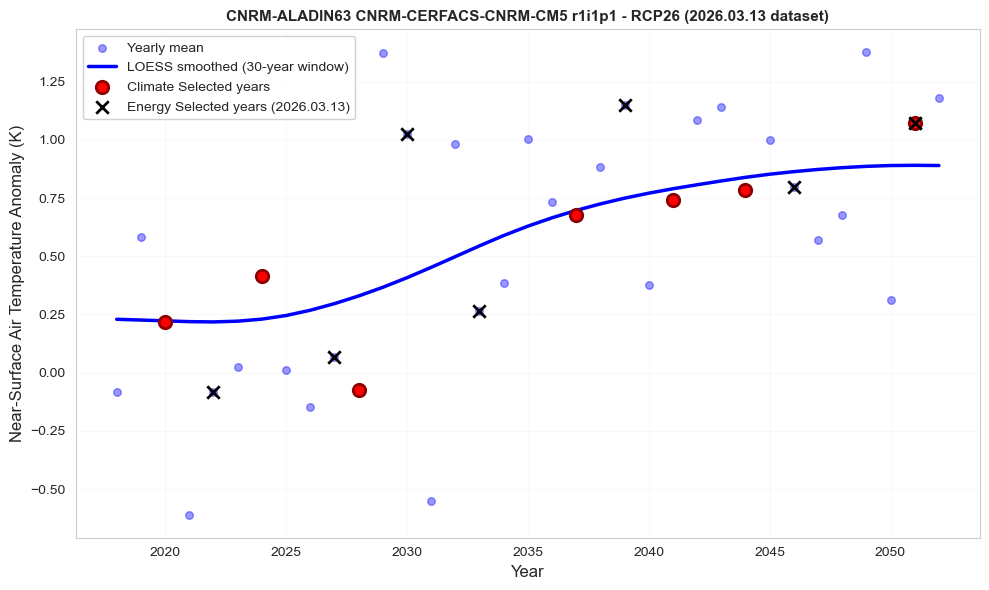

In [29]:

# Temperature anomaly plot - CNRM RCP2.6 only (new 2026.03.13 dataset)
fig, ax = plt.subplots(figsize=(10, 6))
model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
single_model = ds_results["model_chain"].sel(model_scenario=model).item()
single_scenario = ds_results["scenario"].sel(model_scenario=model).item()
units = ds_results.attrs.get("units", "")
years_to_show = np.arange(2018, 2053)
mean_ref = (
    ds_results["tas_yearly"]
    .sel(model_scenario=model)
    .sel(year=np.arange(int(REFERENCE_PERIOD[0]), int(REFERENCE_PERIOD[1]) + 1))
    .mean(dim="year")
    .item()
)
climate_selected_years_26 = selected_years_dict[model]

(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot.scatter(
    ax=ax, alpha=0.4, s=30, color="blue", label="Yearly mean"
)
(ds_results["tas_smoothed"].sel(model_scenario=model) - mean_ref).sel(year=years_to_show).plot(
    ax=ax, linewidth=2.5, color="blue", label="LOESS smoothed (30-year window)"
)
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=climate_selected_years_26).plot.scatter(
    ax=ax, alpha=1, s=80, color="red", marker="o",
    edgecolors="darkred", linewidths=2, label="Climate Selected years", zorder=5
)
(ds_results["tas_yearly"].sel(model_scenario=model) - mean_ref).sel(year=selected_years_26).plot.scatter(
    ax=ax, alpha=1, s=80, color="black", marker="x",
    linewidths=2, label="Energy Selected years (2026.03.13)", zorder=5
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel(f"Near-Surface Air Temperature Anomaly ({units})", fontsize=12)
ax.set_title(
    f"{single_model.replace('_', ' ')} - {single_scenario.upper()} (2026.03.13 dataset)",
    fontsize=11, fontweight="bold"
)
ax.legend(loc="upper left", framealpha=0.9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


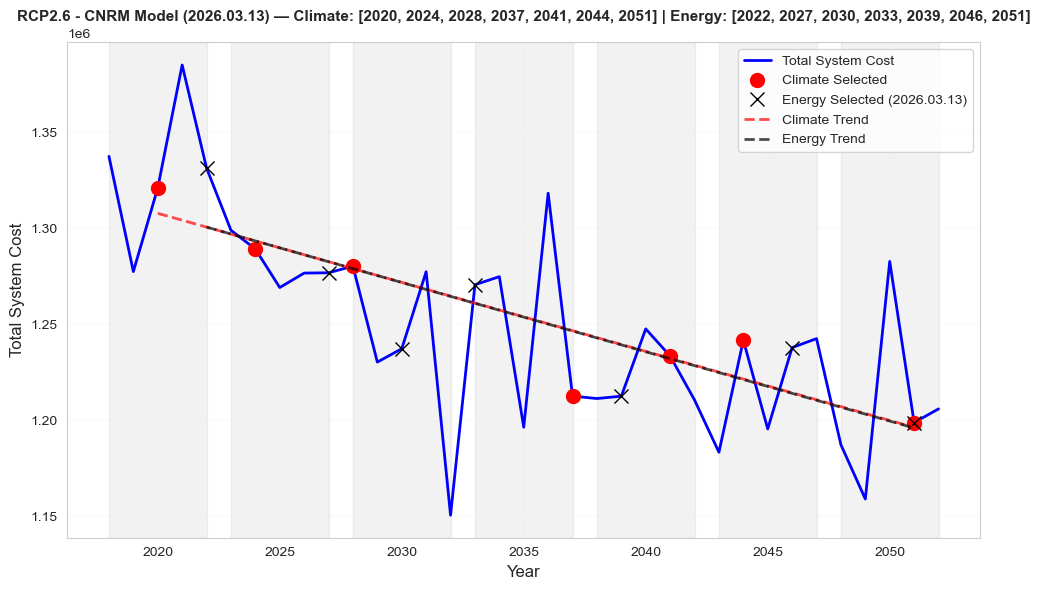

In [31]:

# Cost plot with climate vs energy selected years and trend lines (2026.03.13 dataset, RCP2.6 only)
fig, ax = plt.subplots(figsize=(10, 6))

model = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
climate_selected_years_26 = selected_years_dict[model]

# Track line count before each plot call to relabel added artists correctly,
# since pandas DataFrame.plot() uses column names as labels regardless of label=
n0 = len(ax.lines)
df_cost_26.plot(ax=ax, legend=False, color="blue", linewidth=2)
for l in ax.lines[n0:]:
    l.set_label("Total System Cost")

n1 = len(ax.lines)
df_cost_26.loc[climate_selected_years_26].plot(style="o", color="red", markersize=10, ax=ax, legend=False)
for l in ax.lines[n1:]:
    l.set_label("Climate Selected")

n2 = len(ax.lines)
df_cost_26.loc[selected_years_26].plot(style="x", color="black", markersize=10, ax=ax, legend=False)
for l in ax.lines[n2:]:
    l.set_label("Energy Selected (2026.03.13)")

# Trend line — climate selected years
climate_costs_26 = df_cost_26.loc[climate_selected_years_26].values.flatten()
z_climate_26 = np.polyfit(climate_selected_years_26, climate_costs_26, 1)
ax.plot(
    climate_selected_years_26, np.poly1d(z_climate_26)(climate_selected_years_26),
    linestyle="--", color="red", linewidth=2, alpha=0.7, label="Climate Trend"
)

# Trend line — energy selected years
energy_costs_26 = df_cost_26.loc[selected_years_26].values.flatten()
z_energy_26 = np.polyfit(selected_years_26, energy_costs_26, 1)
ax.plot(
    selected_years_26, np.poly1d(z_energy_26)(selected_years_26),
    linestyle="--", color="black", linewidth=2, alpha=0.7, label="Energy Trend"
)

for start_year in window_start_years:
    ax.axvspan(start_year, start_year + 4, color="gray", alpha=0.1, zorder=0)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total System Cost", fontsize=12)
ax.set_title(
    f"RCP2.6 - CNRM Model (2026.03.13) — Climate: {climate_selected_years_26} | Energy: {selected_years_26}",
    fontsize=11, fontweight="bold"
)
ax.legend(loc="best", fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
